In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)


In [2]:
df = pd.read_csv('train.csv')

df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nSummary Statistics:")
display(df.describe())


Dataset Shape: (614, 13)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB

Summary Statistics:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [4]:

print("Column Names:")
print(df.columns.tolist())


Column Names:
['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


In [5]:

print("Missing Values:")
print(df.isnull().sum())


Missing Values:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [6]:

print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [12]:
print(df['Loan_Status'].value_counts())

Loan_Status
Y    422
N    192
Name: count, dtype: int64


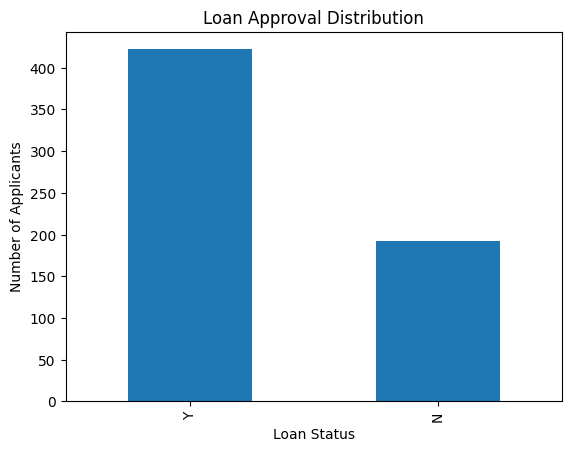

In [13]:
df['Loan_Status'].value_counts().plot(kind='bar')

plt.title("Loan Approval Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.show()

In [14]:
X = df.drop('Loan_Status', axis=1)

y = df['Loan_Status'].map({'N': 0, 'Y': 1})


In [15]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)


Training: (491, 12)
Testing: (123, 12)


In [16]:
num_cols = X_train.select_dtypes(
    include=np.number
).columns

cat_cols = X_train.select_dtypes(
    include='object'
).columns

for col in num_cols:
    value = X_train[col].median()
    X_train[col] = X_train[col].fillna(value)
    X_test[col] = X_test[col].fillna(value)

for col in cat_cols:
    value = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(value)
    X_test[col] = X_test[col].fillna(value)

In [17]:

X_train = pd.get_dummies(
    X_train, drop_first=True, dtype=int
)

X_test = pd.get_dummies(
    X_test, drop_first=True, dtype=int
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)


In [18]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


In [19]:

print("Training class counts:")
print(y_train.value_counts())

print("Testing class counts:")
print(y_test.value_counts())


Training class counts:
Loan_Status
1    337
0    154
Name: count, dtype: int64
Testing class counts:
Loan_Status
1    85
0    38
Name: count, dtype: int64


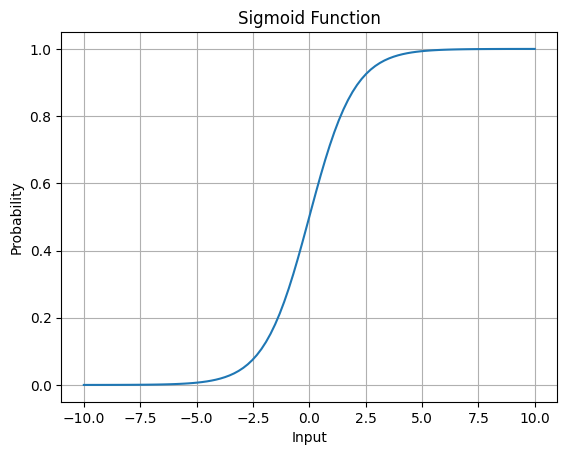

In [20]:

z = np.linspace(-10, 10, 100)

sigmoid = 1 / (1 + np.exp(-z))

plt.plot(z, sigmoid)

plt.title("Sigmoid Function")
plt.xlabel("Input")
plt.ylabel("Probability")
plt.grid()

plt.show()


In [21]:

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Model Training Completed")


Model Training Completed


In [ ]:

print("Intercept:")
print(model.intercept_)

coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_[0]
})

display(coefficients)


In [22]:

y_prob = model.predict_proba(X_test_scaled)[:, 1]

print(y_prob[:10])


[0.25735718 0.96657708 0.93281501 0.92420194 0.96358835 0.95831053
 0.96234439 0.94865233 0.92534933 0.93191705]


In [23]:

y_pred = model.predict(X_test_scaled)

print("Predicted:")
print(y_pred[:10])

print("Actual:")
print(y_test.values[:10])


Predicted:
[0 1 1 1 1 1 1 1 1 1]
Actual:
[0 1 1 1 1 0 1 1 1 1]


In [24]:

results = pd.DataFrame({
    'Actual': y_test.values,
    'Probability': y_prob,
    'Predicted': y_pred
})

display(results.head(10))


,Actual,Probability,Predicted
0,0,0.257357,0
1,1,0.966577,1
2,1,0.932815,1
3,1,0.924202,1
4,1,0.963588,1
5,0,0.958311,1
6,1,0.962344,1
7,1,0.948652,1
8,1,0.925349,1
9,1,0.931917,1


In [25]:

for t in [0.3, 0.5, 0.7]:

    pred = (y_prob >= t).astype(int)

    print("Threshold:", t)
    print("Approved:", sum(pred == 1))
    print("Rejected:", sum(pred == 0))


Threshold: 0.3
Approved: 114
Rejected: 9
Threshold: 0.5
Approved: 102
Rejected: 21
Threshold: 0.7
Approved: 100
Rejected: 23


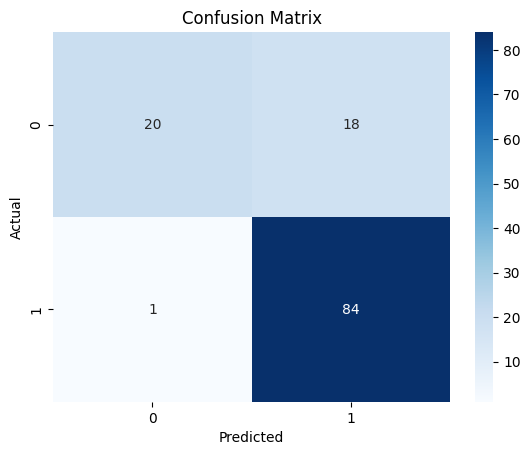

In [26]:

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d',
            cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()


In [27]:

tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

specificity = tn / (tn + fp)

f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1 Score:", f1)


Accuracy: 0.8455284552845529
Precision: 0.8235294117647058
Recall: 0.9882352941176471
Specificity: 0.5263157894736842
F1 Score: 0.8983957219251337


In [28]:

evaluation = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision',
               'Recall', 'Specificity', 'F1-score'],
    'Result': [accuracy, precision,
               recall, specificity, f1]
})

display(evaluation)


,Metric,Result
0,Accuracy,0.845528
1,Precision,0.823529
2,Recall,0.988235
3,Specificity,0.526316
4,F1-score,0.898396


In [29]:

print(classification_report(
    y_test,
    y_pred,
    target_names=['Rejected', 'Approved']
))


              precision    recall  f1-score   support

    Rejected       0.95      0.53      0.68        38
    Approved       0.82      0.99      0.90        85

    accuracy                           0.85       123
   macro avg       0.89      0.76      0.79       123
weighted avg       0.86      0.85      0.83       123



In [30]:

majority = y_train.mode()[0]

baseline = np.full(len(y_test), majority)

print("Baseline Accuracy:",
      accuracy_score(y_test, baseline))

print("Model Accuracy:", accuracy)


Baseline Accuracy: 0.6910569105691057
Model Accuracy: 0.8455284552845529


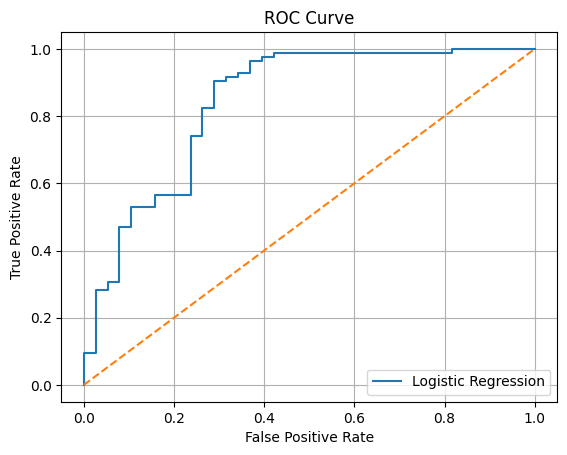

ROC-AUC: 0.8417956656346749


In [31]:

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

roc_auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label='Logistic Regression')

plt.plot([0,1], [0,1], '--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()
plt.grid()
plt.show()

print("ROC-AUC:", roc_auc)


In [32]:

for t in [0.3, 0.5, 0.7]:

    pred = (y_prob >= t).astype(int)

    print("\nThreshold:", t)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred, zero_division=0))
    print("Recall:", recall_score(y_test, pred, zero_division=0))
    print("F1-score:", f1_score(y_test, pred, zero_division=0))



Threshold: 0.3
Accuracy: 0.7479674796747967
Precision: 0.7368421052631579
Recall: 0.9882352941176471
F1-score: 0.8442211055276382

Threshold: 0.5
Accuracy: 0.8455284552845529
Precision: 0.8235294117647058
Recall: 0.9882352941176471
F1-score: 0.8983957219251337

Threshold: 0.7
Accuracy: 0.8617886178861789
Precision: 0.84
Recall: 0.9882352941176471
F1-score: 0.9081081081081082


In [33]:

train_pred = model.predict(X_train_scaled)
test_pred = model.predict(X_test_scaled)

print("Training Accuracy:",
      accuracy_score(y_train, train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, test_pred))


Training Accuracy: 1.0
Testing Accuracy: 0.8455284552845529


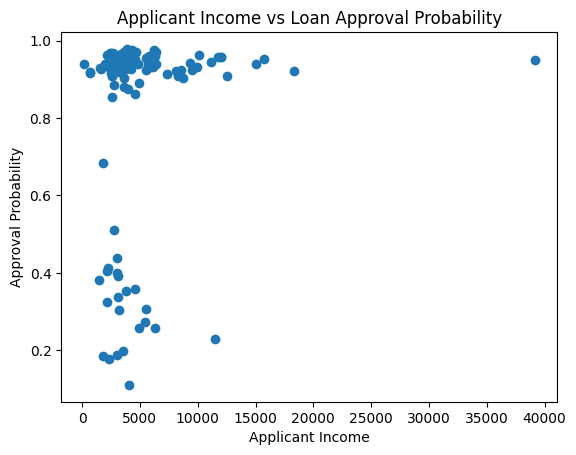

In [34]:

plt.scatter(
    X_test['ApplicantIncome'],
    y_prob
)

plt.xlabel("Applicant Income")
plt.ylabel("Approval Probability")

plt.title("Applicant Income vs Loan Approval Probability")

plt.show()


In [35]:

new_applicant = pd.DataFrame([{
    'Gender': 'Male',
    'Married': 'Yes',
    'Dependents': '0',
    'Education': 'Graduate',
    'Self_Employed': 'No',
    'ApplicantIncome': 5000,
    'CoapplicantIncome': 0,
    'LoanAmount': 120,
    'Loan_Amount_Term': 360,
    'Credit_History': 1,
    'Property_Area': 'Urban'
}])

new_applicant = pd.get_dummies(
    new_applicant,
    drop_first=True,
    dtype=int
)

new_applicant = new_applicant.reindex(
    columns=X_train.columns,
    fill_value=0
)

new_scaled = scaler.transform(new_applicant)

probability = model.predict_proba(new_scaled)[0][1]

prediction = model.predict(new_scaled)[0]

print("Approval Probability:", probability)

if prediction == 1:
    print("Loan Approved")
else:
    print("Loan Rejected")


Approval Probability: 0.9281246043565624
Loan Approved
